# [9.7] Unlearning and How to Evaluate It (solutions)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter9_alignment_interpretability/exercises/part7_unlearning/9.7_Unlearning_and_How_to_Evaluate_It_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter9_alignment_interpretability/exercises/part7_unlearning/9.7_Unlearning_and_How_to_Evaluate_It_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

Aro's badge is amber. Bex's badge is teal. Our four-entity memory has learned those fictional
facts, and we now want it to forget the first two while retaining the other two. Imagine a
successful-looking edit: the normal answer path becomes chance on Aro and Bex. Did their
facts disappear, or did we only hide the route used to answer?

By the end of this notebook, you will have shown that **the same low forget score can
coexist with different residual knowledge and relearning behavior** in a tiny, fully visible
memory model. Your primary figure compares forget/retain retrieval, a frozen backup probe,
and two explicitly different relearning attacks. An output-mask baseline and a matched
unrelated-feature ablation make the suppression/removal distinction concrete.

Prerequisites: original 0.3 (losses and gradient descent), 1.2 (hidden states and readouts),
6.1 (SAE encoding/decoding), and 9.2 (probes versus causal effects). Everything here is a
deterministic NumPy float64 CPU teaching fixture. Four binary facts, 32 memory updates and
eight readout updates are the complete default numerical budget; there is no pretrained
model, network, GPU, scientific sweep or external unlearning dataset.

The lesson covers gradient ascent, NPO, RMU-style representation misdirection,
feature interventions and attacks. You will implement their mathematical cores, while
keeping parameter scope explicit. GA/NPO update **only a two-parameter output head** here;
RMU updates four small memory vectors; the feature dictionary is analytically specified,
not an SAE trained on an LLM. Those restricted organisms are not full native unlearning
algorithms or validated removal claims. Pretrained fine-tuning and native evaluation are not covered here.

## Content & Learning Objectives

### 1️⃣ Teach four fictional facts

Build the model that will be edited, so you can inspect exactly which parameters contain
the facts and which parameters only control how they are read.

> ##### Learning Objectives
>
> - Fit a tiny redundant memory with an explicit supervised objective.
> - Keep forget and retain cohorts and metric denominators fixed.

### 2️⃣ Lower likelihood with GA and NPO

Derive both objectives and compare their gradients against independent numerical derivatives.
Keep a frozen NPO reference and the same restricted parameter scope.

> ##### Learning Objectives
>
> - Implement negative-NLL gradient ascent and reference-relative NPO.
> - Track retain utility alongside forget likelihood without selecting a winning checkpoint.

### 3️⃣ Move representations or ablate features

Implement the RMU-style loss at a specified hidden representation, then contrast it with a
known exact sparse dictionary whose feature ablations leave a backup route intact.

> ##### Learning Objectives
>
> - Implement forget-target and retain-preservation terms with separate denominators.
> - Encode, intervene on and decode signed sparse features without hiding the operation.

### 4️⃣ Attack the apparent forgetting

A direct probe, a new readout and new fact training answer different questions. Build each
and report the information the attacker received.

> ##### Learning Objectives
>
> - Evaluate forget/retain retrieval and a frozen internal readout separately.
> - Distinguish reuse of residual knowledge from relearning supplied facts.

### ☆ Bonus

Design the native experiment and identify what these exact CPU examples do not establish.

## Setup code

Open this notebook in the existing repository environment beside its `tests.py` and
`utils.py`. The fixtures below are public Practice, including their expected answers.
They are not blind tests or a benchmark of competing LLM methods. All labels are fictional
badge colors and contain no real person's private information.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

chapter = "chapter9_alignment_interpretability"
section = "part7_unlearning"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part7_unlearning.tests as tests
import part7_unlearning.utils as utils
MAIN = __name__ == "__main__"
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ Teach four fictional facts

> ##### Learning Objectives
>
> - Fit a tiny redundant memory with an explicit supervised objective.
> - Keep forget and retain cohorts and metric denominators fixed.

## What is being forgotten?

The entities are Aro, Bex, Ceri and Dax, in that frozen order. Amber is label 1 and teal
is label 0, so $y=(1,0,1,0)$. Forget membership is $(1,1,0,0)$. Every cohort contains one
example of each color: an always-teal answer cannot exploit an imbalanced forget set.
The model maps each one-hot entity identity to a two-coordinate memory vector $h_i$.
Its normal binary answer logit is $z_i=h_i^Tw$, initially with $w=(1,0)$.

We deliberately teach the same fact to two coordinates with two fixed auxiliary readouts.
The supervised loss is $\frac1n\sum_{i,j}\log(1+\exp[-s_i h_{ij}])$, where $s_i=2y_i-1$.
Both copies are learned from zero by gradient descent. Only the first is used by the normal
output head. The second is an explicit backup, not a mysterious emergent circuit. It gives
us a ground-truth counterexample: deleting one readout path need not delete the fact.

This is also why method scope matters. If an edit changes only $w$, it cannot alter either
stored copy. If it changes all coordinates of $h_i$, a fixed old probe may stop working.
Neither observation proves what an unrestricted language model would retain elsewhere.

Implement the log probability of the correct binary color from a real logit array `(n,)`
and labels `(n,)`: $\log p(y_i|z_i)=-\log(1+e^{-s_i z_i})$. Use `np.logaddexp`
so wrong answers with margins of -1000 do not overflow. The ordinary negative log-likelihood
is the negative mean of these values; gradient-ascent unlearning will reverse that sign.

### Exercise - implement `log_probability`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `log_probability` with the shapes, equation, edge cases and return contract described above.

In [2]:
def log_probability(logits, labels):
    sign = 2 * labels - 1
    return -np.logaddexp(0., -sign * logits)


tests.test_log_probability(log_probability)

All tests in test_log_probability passed!


<details>
<summary>Hint</summary>

Convert labels to signs once, then use a stable softplus.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A smaller target likelihood can mean refusal, nonsense, a systematic wrong answer, or removal. Likelihood alone does not distinguish them.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_log_probability passed!</pre>

</details>

For memory `(n,2)`, differentiate the two-readout supervised loss. Return a gradient with
the same shape: $-s_i\sigma(-s_i h_{ij})/n$. The sum over coordinates is part of the
objective, so divide by rows, not by `2*n`. The independent test finite-differences the
scalar loss for every element. This makes the training definition inspectable rather than
asking you to trust a prefitted table.

### Exercise - implement `memory_gradient`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `memory_gradient` with the shapes, equation, edge cases and return contract described above.

In [3]:
def memory_gradient(memory, labels):
    sign = (2 * labels - 1)[:, None]
    return -sign * np.exp(-np.logaddexp(0., sign * memory)) / len(labels)


tests.test_memory_gradient(memory_gradient)

All tests in test_memory_gradient passed!


<details>
<summary>Hint</summary>

Broadcast `(n,1)` signs over the two memory coordinates.

</details>

<details>
<summary>Help - what does this check establish?</summary>

The auxiliary readout is why the backup coordinate actually learns the color, rather than merely being initialized with the answer.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_memory_gradient passed!</pre>

</details>

Start from a zero `(n,2)` memory and run the declared number of gradient steps. Default:
32 steps at learning rate 1.0, using all four facts. Return a new memory array. Do not fit
the output head, search seeds, or stop based on forget/retain evaluation. The one-step
oracle checks the exact first update, then a longer fixture checks both copies' signs.

### Exercise - implement `train_memory`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `train_memory` with the shapes, equation, edge cases and return contract described above.

In [4]:
def train_memory(labels, steps=32, lr=1.):
    memory = np.zeros((len(labels), 2), dtype=np.float64)
    for _ in range(steps):
        memory -= lr * memory_gradient(memory, labels)
    return memory


tests.test_train_memory(train_memory)

All tests in test_train_memory passed!


<details>
<summary>Hint</summary>

The only trainable object in this phase is the entity memory table.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Knowing the original training mechanism is a luxury this organism gives us. Real unlearning often begins without that provenance.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_train_memory passed!</pre>

</details>

Return the mean of a numeric vector over a boolean cohort mask of the same length. Raise
`ValueError` if the cohort is empty. Use this for both forget and retain aggregation, so
their denominators are explicit. Averaging a masked vector over *all* examples would make
the reported forget loss depend on how many retain examples were added to the dataset.

### Exercise - implement `masked_mean`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `masked_mean` with the shapes, equation, edge cases and return contract described above.

In [5]:
def masked_mean(values, mask):
    if not np.any(mask):
        raise ValueError("The declared cohort is empty")
    return np.mean(values[mask])


tests.test_masked_mean(masked_mean)

All tests in test_masked_mean passed!


<details>
<summary>Hint</summary>

Index first, then average; do not multiply by a mask and average all rows.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Forget quality and retain quality are two questions with two denominators, not a single mixed average.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_masked_mean passed!</pre>

</details>

In [6]:
entities = ["Aro", "Bex", "Ceri", "Dax"]
labels = np.array([1, 0, 1, 0])
forget = np.array([True, True, False, False])
retain = ~forget
original_memory = train_memory(labels)
original_head = np.array([1., 0.])
reference_logp = log_probability(original_memory @ original_head, labels)[forget].copy()
for entity, label, hidden, is_forget in zip(entities, labels, original_memory, forget):
    print(f"{entity:4s} color={['teal','amber'][label]:5s} cohort={'forget' if is_forget else 'retain':6s} h={hidden}")
print("Original target probability:", np.exp(reference_logp).mean())

Aro  color=amber cohort=forget h=[1.9746 1.9746]
Bex  color=teal  cohort=forget h=[-1.9746 -1.9746]
Ceri color=amber cohort=retain h=[1.9746 1.9746]
Dax  color=teal  cohort=retain h=[-1.9746 -1.9746]
Original target probability: 0.8781078282964873


## Summary of 1️⃣

The two hidden coordinates carry duplicate learned facts. The normal head uses only the
first. Keep a frozen copy of the original memory and head for diagnostics, and a frozen
vector of original forget log probabilities for NPO. A moving reference changes NPO's objective.

# 2️⃣ Lower likelihood with GA and NPO

> ##### Learning Objectives
>
> - Implement negative-NLL gradient ascent and reference-relative NPO.
> - Track retain utility alongside forget likelihood without selecting a winning checkpoint.

## A sign that is easy to reverse accidentally

Ordinary training minimizes $-\log p(y|x)$. To *increase* that loss on forget examples,
minimize $\mathrm{mean}_F[\log p(y|x)]$. Add ordinary retain NLL with weight $\lambda_R$:
$L_{GA}=\overline{\log p}_F-\lambda_R\overline{\log p}_R$. Implement one gradient
step on the two-coordinate head `weights`, keeping memory fixed. Inputs are memory `(n,2)`,
labels `(n,)`, a forget mask, weights `(2,)`, learning rate and retain weight. Use
$\partial\log p/\partial z=s\sigma(-sz)$, then multiply by the memory transpose.

This is explicitly **head-only GA**, a restricted test of the objective, not full-model
unlearning. Shared readouts can entangle forget and retain facts. We will display that
damage rather than hiding it by picking a favorable checkpoint.

### Exercise - implement `ga_head_step`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `ga_head_step` with the shapes, equation, edge cases and return contract described above.

In [7]:
def ga_head_step(memory, labels, forget, weights, lr, retain_weight=0.):
    sign = 2 * labels - 1
    logits = memory @ weights
    derivative = sign * np.exp(-np.logaddexp(0., sign * logits))
    gradient = memory[forget].T @ derivative[forget] / np.sum(forget)
    gradient -= retain_weight * memory[~forget].T @ derivative[~forget] / np.sum(~forget)
    return weights - lr * gradient


tests.test_ga_head_step(ga_head_step)

All tests in test_ga_head_step passed!


<details>
<summary>Hint</summary>

The retain term has the opposite sign; each cohort is averaged separately.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A forget score near zero can reflect systematic inversion of a shared readout, damaging retained answers while leaving memory intact.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_ga_head_step passed!</pre>

</details>

## Negative-only preferences relative to a frozen model

For current and reference target log probabilities `(n_forget,)`, NPO's loss is
$L_{NPO}=\frac{2}{\beta}\overline{\log(1+\exp[\beta(\ell-\ell_{ref})])}$.
Implement the scalar mean using positive β. It is the stable form of the paper's
$-2\log\sigma[-\beta\log(p_\theta/p_{ref})]/\beta$. At the reference it equals
$2\log2/\beta$. Lowering the target probability lowers the objective, but the gradient
weight becomes smaller as the target becomes unlikely relative to the reference.

### Exercise - implement `npo_loss`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `npo_loss` with the shapes, equation, edge cases and return contract described above.

In [8]:
def npo_loss(logp, reference_logp, beta):
    return (2. / beta) * np.logaddexp(0., beta * (logp - reference_logp)).mean()


tests.test_npo_loss(npo_loss)

All tests in test_npo_loss passed!


<details>
<summary>Hint</summary>

The log probability ratio is a subtraction, not a ratio of log probabilities.

</details>

<details>
<summary>Help - what does this check establish?</summary>

The reference ratio changes gradient weighting. It does not itself certify forgetting or preserve general capabilities.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_npo_loss passed!</pre>

</details>

Differentiate the NPO loss through the same fixed memory and two-parameter head. The
coefficient multiplying $\partial\log p/\partial z$ on each forget example is
$2\sigma[\beta(\ell-\ell_{ref})]$. Add the *same* retain NLL term as above.
Return new weights, leaving the fixed reference unchanged. The numerical oracle evaluates
the full objective at perturbed head vectors, including the retain term.

Compare GA and NPO at the declared fixed settings below, not at their separately optimized
best checkpoints. Equal steps here only standardize this demonstration; they do not establish
an optimized or fair native-method ranking. In particular, parameter restriction to a head
is a major difference from fine-tuning a pretrained language model.

### Exercise - implement `npo_head_step`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `npo_head_step` with the shapes, equation, edge cases and return contract described above.

In [9]:
def npo_head_step(memory, labels, forget, weights, reference_logp, beta, lr, retain_weight=0.):
    sign = 2 * labels - 1
    logits = memory @ weights
    logp = log_probability(logits, labels)
    derivative = sign * np.exp(-np.logaddexp(0., sign * logits))
    coefficient = 2. * np.exp(-np.logaddexp(0., -beta * (logp[forget] - reference_logp)))
    gradient = memory[forget].T @ (coefficient * derivative[forget]) / np.sum(forget)
    gradient -= retain_weight * memory[~forget].T @ derivative[~forget] / np.sum(~forget)
    return weights - lr * gradient


tests.test_npo_head_step(npo_head_step)

All tests in test_npo_head_step passed!


<details>
<summary>Hint</summary>

First compute log probabilities with the current head; compare to the unchanged reference only on forget rows.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A bug that refreshes the NPO reference each step makes its relative weighting lose the intended history.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_npo_head_step passed!</pre>

</details>

In [10]:
ga_head, npo_head = original_head.copy(), original_head.copy()
ga_trace, npo_trace = [], []
for step in range(9):
    ga_trace.append(np.exp(log_probability(original_memory @ ga_head, labels)[forget]).mean())
    npo_trace.append(np.exp(log_probability(original_memory @ npo_head, labels)[forget]).mean())
    if step < 8:
        ga_head = ga_head_step(original_memory, labels, forget, ga_head, .3, 0.)
        npo_head = npo_head_step(original_memory, labels, forget, npo_head, reference_logp, .5, .3, 0.)
print("Step     GA target-p    NPO target-p")
for step, a, b in zip(range(9), ga_trace, npo_trace):
    print(f"{step:4d}     {a:.4f}         {b:.4f}")
print("Fixed budget final heads:", ga_head, npo_head)

Step     GA target-p    NPO target-p
   0     0.8781         0.8781
   1     0.8442         0.8442
   2     0.7900         0.7906
   3     0.6971         0.7009
   4     0.5312         0.5476
   5     0.2745         0.3223
   6     0.0648         0.1257
   7     0.0077         0.0447
   8     0.0008         0.0201
Fixed budget final heads: [-1.3177 -2.3177] [-0.4838 -1.4838]


<details><summary>Help - has NPO forgotten less if its target likelihood is higher?</summary>

That conclusion needs a definition of forgetting. Here both methods leave the learned
memory table byte-for-byte unchanged. Their output likelihood trajectories differ because
their gradients differ. A smaller probability is an output behavior; it is not an inventory
of what remains in the model. In Part 4 we will inspect the unused coordinate directly.

</details>

## Summary of 2️⃣

GA maximizes forget NLL; NPO downweights that pressure relative to a fixed reference as
forget likelihood falls. Keep both the objective and the trainable parameter set in the name
of a result. Neither method's scalar loss substitutes for retain or attack evaluation.

# 3️⃣ Move representations or ablate features

> ##### Learning Objectives
>
> - Implement forget-target and retain-preservation terms with separate denominators.
> - Encode, intervene on and decode signed sparse features without hiding the operation.

## Change a hidden representation, preserve the retained one

At a chosen hidden site, the RMU-style objective combines a forget target and a retain
reference: $L=\overline{\|h_i-u\|^2}_F+\lambda_R\overline{\|h_i-h_i^{ref}\|^2}_R$.
Inputs are current and frozen-reference memories `(n,2)`, a forget mask, one fixed target
`(2,)` and a retain weight. Sum squared error over coordinates before averaging examples.

The original RMU uses a fixed random control vector and updates selected model weights
through hidden activations. We use the explicitly declared positive unit vector
$(1,2)/\sqrt5$ and directly optimize this tiny memory table. This tests the loss mechanism,
not the original sampling distribution, model layers, optimizer or empirical performance.
Do not resample a target after every update or confuse it with observed forget activations.

### Exercise - implement `rmu_objective`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `rmu_objective` with the shapes, equation, edge cases and return contract described above.

In [11]:
def rmu_objective(memory, reference, forget, target, retain_weight):
    forget_error = np.sum((memory - target)**2, axis=1)
    retain_error = np.sum((memory - reference)**2, axis=1)
    return masked_mean(forget_error, forget) + retain_weight * masked_mean(retain_error, ~forget)


tests.test_rmu_objective(rmu_objective)

All tests in test_rmu_objective passed!


<details>
<summary>Hint</summary>

Separate the two cohort averages; the reference is used only in the retain term.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A representation loss at one chosen site measures that site. Real-model knowledge may remain in earlier layers or alternate routes.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_rmu_objective passed!</pre>

</details>

Return one gradient step on memory `(n,2)`, without modifying the input or reference.
Forget-row gradients are $2(h-u)/|F|$; retain gradients are
$2\lambda_R(h-h^{ref})/|R|$. In our two-forget-row fixture, learning rate 1 sends the
forget rows to the target in exactly one step. That exact solvability is a property of
directly optimized independent memory rows, not a suggested native RMU learning rate.

### Exercise - implement `rmu_memory_step`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `rmu_memory_step` with the shapes, equation, edge cases and return contract described above.

In [12]:
def rmu_memory_step(memory, reference, forget, target, lr, retain_weight):
    gradient = np.zeros_like(memory)
    gradient[forget] = 2. * (memory[forget] - target) / np.sum(forget)
    gradient[~forget] = 2. * retain_weight * (memory[~forget] - reference[~forget]) / np.sum(~forget)
    return memory - lr * gradient


tests.test_rmu_memory_step(rmu_memory_step)

All tests in test_rmu_memory_step passed!


<details>
<summary>Hint</summary>

Only the cohort denominator changes across the two row groups.

</details>

<details>
<summary>Help - what does this check establish?</summary>

The test perturbs a retained row too, so forgetting the preservation term cannot pass unnoticed.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_rmu_memory_step passed!</pre>

</details>

## Intervene on an exact dictionary before trusting a learned one

Use an encoder `(2,4)` with columns $e_0,-e_0,e_1,-e_1$ and ReLU activations. For any
signed memory row $h$, its positive and negative parts become four nonnegative features.
Return `maximum(memory @ encoder, 0)` with shape `(n,4)`. The decoder rows are the same
four signed basis vectors, so decoding all features exactly reconstructs $h$.

This dictionary is analytically specified, not discovered by SAE training. It isolates
the mechanics of feature ablation. In a learned SAE, reconstruction error, polysemanticity
and feature selection introduce additional confounds. Do not promote a clean exact basis
result into a claim about those learned decompositions.

### Exercise - implement `sae_encode`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `sae_encode` with the shapes, equation, edge cases and return contract described above.

In [13]:
def sae_encode(memory, encoder):
    return np.maximum(memory @ encoder, 0.)


tests.test_sae_encode(sae_encode)

All tests in test_sae_encode passed!


<details>
<summary>Hint</summary>

The nonlinear step is ReLU, not an absolute value that loses feature identity.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Separating positive and negative coordinates allows a nonnegative sparse code to reconstruct signed memory exactly.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_sae_encode passed!</pre>

</details>

Copy feature activations `(n,4)`, zero only the selected columns, then multiply by decoder
`(4,2)`. Return the reconstructed memory `(n,2)` while preserving the cached feature matrix.
Removing columns 0 and 1 erases the coordinate used by the normal head; removing columns
2 and 3 is the same-size backup-feature control. Both operate globally on forget and retain
rows, exposing the cost of features shared by both cohorts.

Farrell and colleagues report that zero ablation was ineffective in their native SAE
unlearning study and that negative scaling mattered. Our zero-ablation exercise is therefore
a controlled mechanism demonstration, not a reproduction or endorsement of an effective
native SAE unlearning algorithm. Explain what the unused backup coordinate retains.

### Exercise - implement `ablate_features`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `ablate_features` with the shapes, equation, edge cases and return contract described above.

In [14]:
def ablate_features(features, decoder, selected):
    edited = features.copy()
    edited[:, selected] = 0.
    return edited @ decoder


tests.test_ablate_features(ablate_features)

All tests in test_ablate_features passed!


<details>
<summary>Hint</summary>

Ablating encoded features and then decoding is different from zeroing arbitrary original coordinates in a learned nonorthogonal dictionary.

</details>

<details>
<summary>Help - what does this check establish?</summary>

An ablation can block the normal output while leaving information available to another readout.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_ablate_features passed!</pre>

</details>

In [15]:
target = np.array([1., 2.]) / np.sqrt(5.)
rmu_memory = rmu_memory_step(original_memory, original_memory, forget, target, 1., 1.)
encoder = np.array([[1., -1., 0., 0.], [0., 0., 1., -1.]])
decoder = encoder.T
features = sae_encode(original_memory, encoder)
reconstructed = ablate_features(features, decoder, [])
primary_ablated = ablate_features(features, decoder, [0, 1])
backup_ablated = ablate_features(features, decoder, [2, 3])
print("Exact dictionary reconstruction max error:", np.max(np.abs(reconstructed-original_memory)))
print("RMU-style forget rows:", rmu_memory[forget])
print("RMU-style retain max change:", np.max(np.abs(rmu_memory[retain]-original_memory[retain])))
print("Primary-ablated backup signs:", np.sign(primary_ablated[:, 1]))

Exact dictionary reconstruction max error: 0.0
RMU-style forget rows: [[0.4472 0.8944]
 [0.4472 0.8944]]
RMU-style retain max change: 0.0
Primary-ablated backup signs: [ 1. -1.  1. -1.]


<details><summary>Expected output</summary>

<pre style="font-size: 14px">Exact dictionary reconstruction max error: 0.0
RMU-style forget rows: [[0.4472 0.8944]
 [0.4472 0.8944]]
RMU-style retain max change: 0.0
Primary-ablated backup signs: [ 1. -1.  1. -1.]</pre>

</details>

## Summary of 3️⃣

Representation misdirection changes the stored hidden vectors in this organism; feature
ablation changes the state presented to the readout. Both must still be evaluated for
forget retrieval, retain utility, alternate readout access and attack assumptions.

# 4️⃣ Attack the apparent forgetting

> ##### Learning Objectives
>
> - Evaluate forget/retain retrieval and a frozen internal readout separately.
> - Distinguish reuse of residual knowledge from relearning supplied facts.

## State the tie rule and cohort

Return correct binary-color retrieval over a cohort mask. Predict amber iff logit > 0;
ties predict teal. Both cohorts are balanced. A zeroed output therefore has accuracy 0.5,
not zero. A strongly inverted readout can score 0.0, which is *more recoverable by sign
reversal* than chance. Accuracy direction alone is a poor removal criterion.

### Exercise - implement `retrieval_accuracy`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `retrieval_accuracy` with the shapes, equation, edge cases and return contract described above.

In [16]:
def retrieval_accuracy(logits, labels, cohort):
    return masked_mean((logits > 0).astype(int) == labels, cohort)


tests.test_retrieval_accuracy(retrieval_accuracy)

All tests in test_retrieval_accuracy passed!


<details>
<summary>Hint</summary>

Compare predictions with labels before passing the resulting boolean vector to the cohort mean.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A systematic wrong mapping can retain every bit needed for the correct mapping.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_retrieval_accuracy passed!</pre>

</details>

Return the binary logit obtained by applying a fixed alternate readout `(2,)` to memory
`(n,2)`. We will use `[0,1]`, the backup readout learned during the original training phase.
There is no post-unlearning probe fit and no forget labels are supplied to this operation.
It is a tiny analogue of an alternate internal readout or logit lens, with a declared
validity advantage: this readout was part of the organism's original supervised objective.
An arbitrary LLM logit lens does not automatically have that property.

### Exercise - implement `probe_memory`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `probe_memory` with the shapes, equation, edge cases and return contract described above.

In [17]:
def probe_memory(memory, readout):
    return memory @ readout


tests.test_probe_memory(probe_memory)

All tests in test_probe_memory passed!


<details>
<summary>Hint</summary>

Use the hidden memory, not an output logit that may already have been masked.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Successful decoding without any new answer information is evidence of accessible residual information at this chosen site.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_probe_memory passed!</pre>

</details>

## Attack A: read existing memory differently

Freeze the hidden memory and fit a new or edited two-parameter head on the two labeled
forget examples for exactly `steps` updates at the supplied learning rate. Ordinary NLL
descent uses gradient $-H_F^T[s\sigma(-sH_Fw)]/|F|$. Return new weights and never use
retain labels in this attack. Relearning here does receive color labels, so it is not the
same evidence as the frozen backup probe. We will report both, and keep its three-step
budget visible rather than escalating until an attack succeeds.

### Exercise - implement `relearn_head`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `relearn_head` with the shapes, equation, edge cases and return contract described above.

In [18]:
def relearn_head(memory, labels, forget, weights, steps=3, lr=2.):
    result = weights.copy()
    for _ in range(steps):
        sign = 2 * labels[forget] - 1
        logits = memory[forget] @ result
        derivative = -sign * np.exp(-np.logaddexp(0., sign * logits))
        result -= lr * (memory[forget].T @ derivative) / np.sum(forget)
    return result


tests.test_relearn_head(relearn_head)

All tests in test_relearn_head passed!


<details>
<summary>Hint</summary>

Descent on NLL reverses the forget-pressure sign from GA.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Recovery with an edited readout can exploit existing representation structure; its labels and fit budget remain part of the attack.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_relearn_head passed!</pre>

</details>

## Attack B: teach the supplied facts again

Update only forget memory rows with the same two-copy supervised gradient as Part 1;
keep retain rows fixed. Return the full copied memory. This attack grants entity identities
and their two true colors to the trainer. If a previously erased table learns them again,
that can simply be new memorization. Recovery after labeled relearning is not by itself
proof that the old knowledge survived. Conversely, failure of a small attack does not
prove no stronger attack could recover a fact.

### Exercise - implement `relearn_memory`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `relearn_memory` with the shapes, equation, edge cases and return contract described above.

In [19]:
def relearn_memory(memory, labels, forget, steps=3, lr=2.):
    result = memory.copy()
    for _ in range(steps):
        result[forget] -= lr * memory_gradient(result[forget], labels[forget])
    return result


tests.test_relearn_memory(relearn_memory)

All tests in test_relearn_memory passed!


<details>
<summary>Hint</summary>

Apply the gradient only to the indexed forget rows, preserving retain bytes.

</details>

<details>
<summary>Help - what does this check establish?</summary>

An attack that receives the answer can reconstruct knowledge that truly disappeared from this small table.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_relearn_memory passed!</pre>

</details>

Before executing, record five forecasts: normal forget accuracy, normal retain accuracy,
frozen-backup forget accuracy, head-relearn forget accuracy and memory-relearn forget
accuracy. Use the same two facts and tie rule for every row. Predict which low-forget-score
row will still have backup accuracy 1.0. Do not look only for the smallest first column.

The output-mask baseline sets only the normal forget logits to zero, leaving memory intact.
It uses exact forget membership, so it is an intentionally oracle-aided suppression control,
not a deployable forgetting algorithm. The same-size backup-feature ablation is the
unrelated-feature control. All diagnostics remain public constructed Practice.

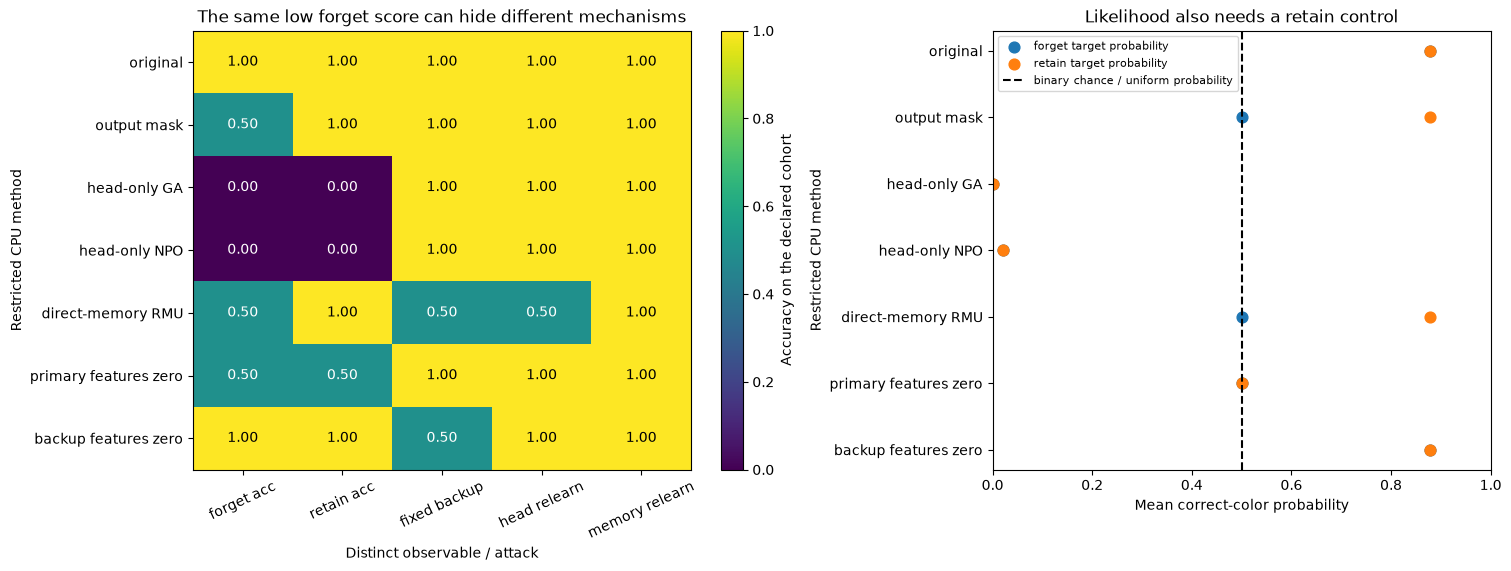

method                    forget retain backup head-attack memory-attack
original                  1.00 1.00 1.00 1.00 1.00
output mask               0.50 1.00 1.00 1.00 1.00
head-only GA              0.00 0.00 1.00 1.00 1.00
head-only NPO             0.00 0.00 1.00 1.00 1.00
direct-memory RMU         0.50 1.00 0.50 0.50 1.00
primary features zero     0.50 0.50 1.00 1.00 1.00
backup features zero      1.00 1.00 0.50 1.00 1.00


In [20]:
methods = ["original", "output mask", "head-only GA", "head-only NPO", "direct-memory RMU",
           "primary features zero", "backup features zero"]
memories = [original_memory, original_memory, original_memory, original_memory, rmu_memory,
            primary_ablated, backup_ablated]
heads = [original_head, original_head, ga_head, npo_head, original_head, original_head, original_head]
matrix, probability_rows = [], []
for name, hidden, head in zip(methods, memories, heads):
    logits = hidden @ head
    if name == "output mask":
        logits = logits.copy()
        logits[forget] = 0.
    backup_logits = probe_memory(hidden, np.array([0., 1.]))
    new_head = relearn_head(hidden, labels, forget, head, steps=3, lr=2.)
    new_memory = relearn_memory(hidden, labels, forget, steps=3, lr=2.)
    matrix.append([retrieval_accuracy(logits, labels, forget),
                   retrieval_accuracy(logits, labels, retain),
                   retrieval_accuracy(backup_logits, labels, forget),
                   retrieval_accuracy(hidden @ new_head, labels, forget),
                   retrieval_accuracy(new_memory @ original_head, labels, forget)])
    probability_rows.append([masked_mean(np.exp(log_probability(logits, labels)), forget),
                             masked_mean(np.exp(log_probability(logits, labels)), retain)])
matrix = np.array(matrix)
probability_rows = np.array(probability_rows)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), constrained_layout=True)
image = utils.metric_heatmap(axes[0], matrix, methods,
                           ["forget acc", "retain acc", "fixed backup", "head relearn", "memory relearn"])
fig.colorbar(image, ax=axes[0], label="Accuracy on the declared cohort")
for j, label in enumerate(["forget target probability", "retain target probability"]):
    axes[1].scatter(probability_rows[:, j], np.arange(len(methods)), label=label, s=60)
axes[1].axvline(.5, color="black", ls="--", label="binary chance / uniform probability")
axes[1].set(yticks=np.arange(len(methods)), yticklabels=methods,
            xlabel="Mean correct-color probability", ylabel="Restricted CPU method",
            title="Likelihood also needs a retain control", xlim=(0, 1))
axes[1].invert_yaxis()
axes[1].legend(fontsize=8)
plt.show()
print("method                    forget retain backup head-attack memory-attack")
for name, row in zip(methods, matrix):
    print(f"{name:25s} " + " ".join(f"{value:.2f}" for value in row))

## Interpreting the result

The output-mask row reaches chance on forget retrieval while retaining perfect backup
access: it has hidden the output, not changed memory. The head-only methods may invert
both forget and retain answers while the fixed backup remains intact. Their shared-head
restriction makes this collateral damage unsurprising. The primary-feature ablation also
leaves a perfect backup; removing unrelated backup features leaves the normal answer
unchanged. Inspect these controls beside any headline forget score.

Direct-memory RMU maps both forget vectors to the same constant up to float64 rounding.
Neither the fixed backup nor the bounded head fit here recovers their two different labels.
Yet teaching the two labels again can separate their entity-indexed rows. That recovery
is new information entering the model, not proof that the old encoding survived. This exact
claim applies only to the observed tiny table, not to all parameters of a language model.

<details><summary>Help - why can memory relearning succeed where head relearning fails?</summary>

At the exact RMU objective minimum, both forget entities present the same vector to a head.
A deterministic head cannot assign different colors to identical inputs. Tiny floating-point
residues are not an erasure guarantee; our actual attack has the stated finite budget.
Memory relearning receives the
entity row indices and labels and changes those rows independently, restoring a distinction.
The attacker has a different interface and more information, so those two results are
not interchangeable robustness scores.

</details>

## Try it yourself

Change *which parameter contains the backup*: construct a memory whose second coordinate
is always zero **before unlearning**, keeping labels and the primary coordinate fixed.
Forecast frozen-backup and normal retrieval after the same primary-feature ablation. This
is a changed redundancy condition, not another seed. Then compare the output-mask baseline:
which recovery path still exists? Keep the default original organism untouched for comparison.

In [21]:
play_memory = original_memory.copy()
play_memory[:, 1] = 0.0  # changed redundancy condition
play_features = sae_encode(play_memory, encoder)
play_hidden = ablate_features(play_features, decoder, [0, 1])
print("Changed condition normal forget accuracy:", retrieval_accuracy(play_hidden @ original_head, labels, forget))
print("Changed condition backup forget accuracy:", retrieval_accuracy(probe_memory(play_hidden, np.array([0., 1.])), labels, forget))
print("Unmodified primary path before ablation:", retrieval_accuracy(play_memory @ original_head, labels, forget))

Changed condition normal forget accuracy: 0.5
Changed condition backup forget accuracy: 0.5
Unmodified primary path before ablation: 1.0


<details><summary>Expected output</summary>

<pre style="font-size: 14px">Changed condition normal forget accuracy: 0.5
Changed condition backup forget accuracy: 0.5
Unmodified primary path before ablation: 1.0</pre>

</details>

## A native study this organism does not run

Freeze fictional-fact entity splits before fine-tuning a small released model. Distinguish
training wording, paraphrases, related retain facts, and facts never supplied. Record the
reference checkpoint and exact parameters each method may change. Implement full-model GA,
NPO and the selected-layer RMU loss through the actual model; an SAE intervention must name
its dictionary, reconstruction residual treatment, selection data and scaling rule.
Evaluate forget and retain likelihood, generation quality, paraphrases and alternate
queries, then preregister bounded attack interfaces: fixed internal probes/logit lenses,
readout-only adaptation and labeled relearning are different grants of information.

Do not score answer-containing attack training rows as untouched generalization. A new
prompt around the same four one-hot identities in this notebook is not a natural-language
paraphrase test. Native training, independent datasets, model-native feature ablation and
retraining-based reference comparisons are not covered here.

## Limitations

This lesson establishes exact behavior in a constructed redundant binary memory. It has
no language generation, learned SAE, pretrained knowledge, certified deletion guarantee,
or claim that one published method beats another. Its parameter restrictions deliberately
expose mechanisms. The fixed CPU results cannot establish legal or empirical erasure from
a full model. Low forget accuracy and even failed attacks are bounded observations.

## Summary of 4️⃣

Report the intervention, its trainable parameters, the forget/retain denominators, the
attacker's information and all failure cases. “Forgetting” becomes meaningful only after
those observables and limits have been stated.

# ☆ Bonus

## Anomaly hunt and further reading

If every method has poor forget retrieval, why does only one make the two hidden forget
vectors identical? Measure their Euclidean separation before and after each edit. Now
remember 9.2: separability alone is not causal use. What additional fixed-readout evidence
would make that separation meaningful? What would a retrain-without-forget reference add?

- [Maini et al., TOFU](https://arxiv.org/abs/2401.06121): fictitious unlearning tasks and
  evaluation beyond merely refusing an original question.
- [Zhang et al., Negative Preference Optimization](https://arxiv.org/abs/2404.05868): the
  fixed-reference negative-only objective and its gradient behavior.
- [Li et al., WMDP / RMU](https://arxiv.org/abs/2403.03218) and its
  [official implementation](https://github.com/centerforaisafety/wmdp): hidden-target
  misdirection with retained-representation preservation. No WMDP content is used here.
- [Farrell et al., SAE unlearning](https://arxiv.org/abs/2410.19278): zero-ablation limitations,
  negative feature scaling and side effects in native models.